IMPORT DAN DATA MENTAH

In [4]:
import kagglehub
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, export_text

# 1. Download dataset (ini akan mendefinisikan variabel 'path')
path = kagglehub.dataset_download("uciml/student-alcohol-consumption")
print("Path to dataset files:", path)

# 2. Tentukan file spesifik (student-mat.csv)
file_path = os.path.join(path, "student-mat.csv")

# 3. Load ke Pandas DataFrame
df = pd.read_csv(file_path)

# --- OUTPUT 1: Tabel Informasi Dataset ---
print("\n### Informasi Dataset ###")
df.info()
display(df.head(6))

Path to dataset files: C:\Users\hi\.cache\kagglehub\datasets\uciml\student-alcohol-consumption\versions\2

### Informasi Dataset ###
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null   

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15


KLASIFIKASI DATA

In [9]:
# Membuat Dictionary Klasifikasi
data_klasifikasi = {
    'Nilai': [1, 2, 3, 4, 5],
    'Keterangan': ['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']
}

# Menampilkan dalam bentuk Tabel
df_klasifikasi = pd.DataFrame(data_klasifikasi)
print("### TABEL REFERENSI KLASIFIKASI ###")
display(df_klasifikasi)

### TABEL REFERENSI KLASIFIKASI ###


,Nilai,Keterangan
0,1,Sangat Rendah
1,2,Rendah
2,3,Sedang
3,4,Tinggi
4,5,Sangat Tinggi


DECISION TREE

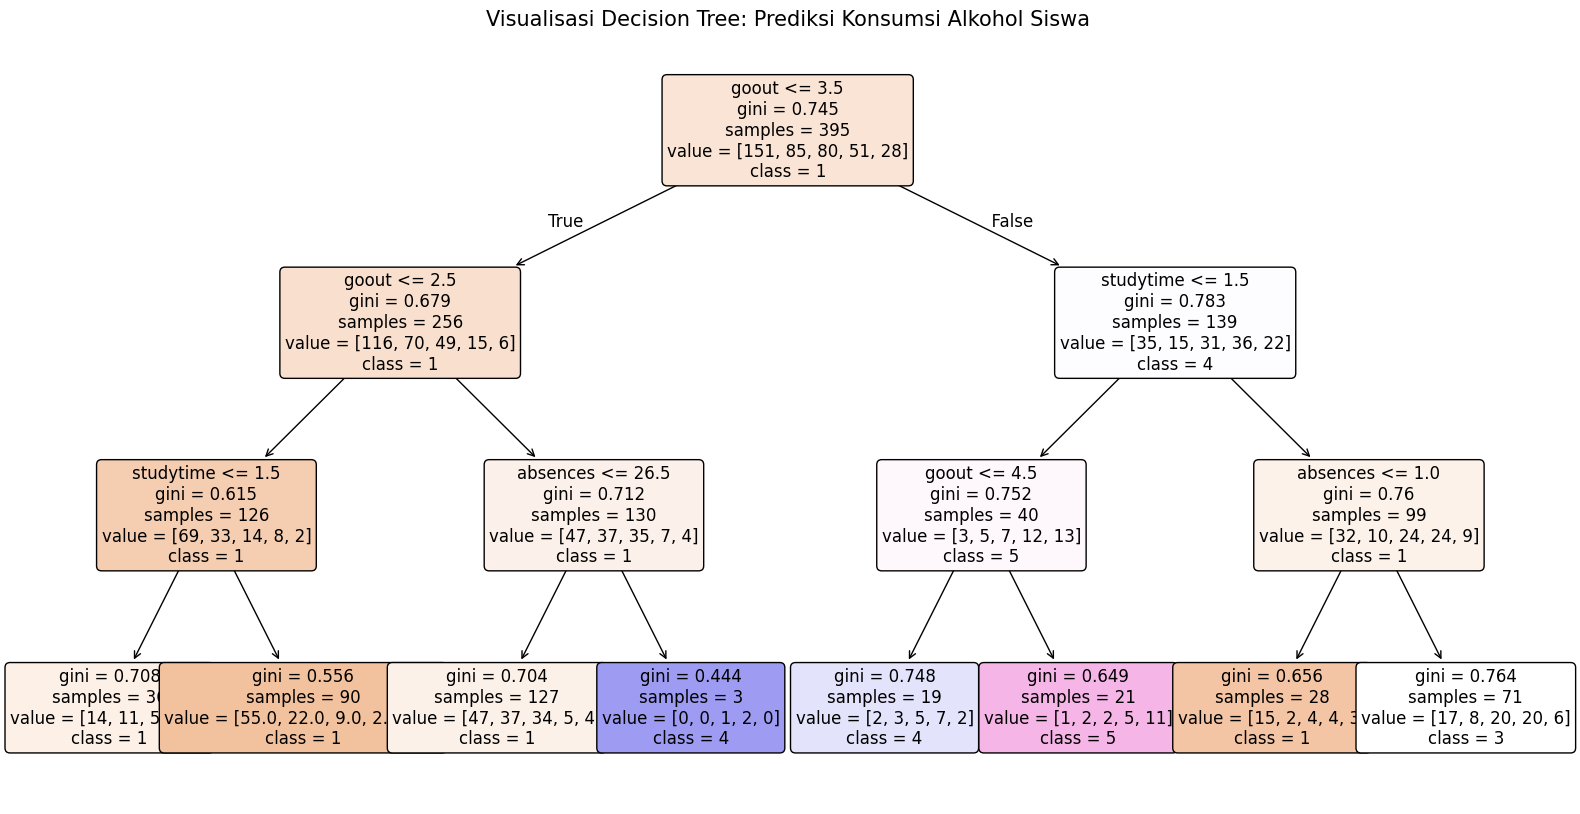

In [ ]:
# menggunakan fitur yang berpengaruh: studytime, failures, goout, dan health
features = ['studytime', 'failures', 'goout', 'health', 'absences']
X = df[features]
y = df['Walc'] # Weekend Alcohol Consumption (1 - sangat rendah, 5 - sangat tinggi)

# Membuat dan melatih model Decision Tree
# max_depth=3 agar pohon tidak terlalu besar dan mudah dibaca
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf = clf.fit(X, y)

# Visualisasi Pohon
plt.figure(figsize=(20,10))
tree.plot_tree(clf, 
               feature_names=features,  
               class_names=[str(i) for i in sorted(df['Walc'].unique())],
               filled=True, 
               rounded=True,
               fontsize=12)
plt.title("Visualisasi Decision Tree: Prediksi Konsumsi Alkohol Siswa", fontsize=15)
plt.show()

In [9]:
pip install jinja2



   ---------------------------------------- 0/2 [MarkupSafe]
   ---------------------------------------- 0/2 [MarkupSafe]
   ---------------------------------------- 0/2 [MarkupSafe]
   ---------------------------------------- 0/2 [MarkupSafe]
   ---------------------------------------- 0/2 [MarkupSafe]
   ---------------------------------------- 0/2 [MarkupSafe]
   ---------------------------------------- 0/2 [MarkupSafe]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]

Note: you may need to restart the kernel to use updated packages.


DECISION TABLE

In [13]:
# Mendefinisikan ulang map untuk kolom keterangan
alkohol_map = dict(zip(data_klasifikasi['Nilai'], data_klasifikasi['Keterangan']))

# Membuat tabel hasil dengan 5 data saja
decision_table = df[features].head(5).copy()

# Melakukan prediksi menggunakan model (clf)
prediksi_angka = clf.predict(df[features].head(5))

# Mengisi kolom hasil keputusan
decision_table['Hasil_Keputusan (Angka)'] = prediksi_angka
decision_table['Keterangan_Konsumsi'] = decision_table['Hasil_Keputusan (Angka)'].map(alkohol_map)
decision_table['Status'] = (prediksi_angka == y[:5]).map({True: 'Sesuai', False: 'Berbeda'})

print("### DECISION TABLE: HASIL PREDIKSI (5 SAMPEL) ###")
display(decision_table)

### DECISION TABLE: HASIL PREDIKSI (5 SAMPEL) ###


,studytime,failures,goout,health,absences,Hasil_Keputusan (Angka),Keterangan_Konsumsi,Status
0,2,0,4,3,6,3,Sedang,Berbeda
1,2,0,3,3,4,1,Sangat Rendah,Sesuai
2,2,3,2,3,10,1,Sangat Rendah,Berbeda
3,3,0,2,5,2,1,Sangat Rendah,Sesuai
4,2,0,2,5,4,1,Sangat Rendah,Berbeda
